# *1.2 Mempelajari Penggunaan Driver Neo4J*

1. Ikuti tutorial penggunaan driver Neo4J untuk melakukan pembuatan objek dan akses objek berikut.

2. Baris berikut mendefinisikan string koneksi ke database Neo4J:

In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "bolt://localhost:7687"  
AUTH = ("neo4j", "kelasgraf23a")

3. Baris perintah berikut melakukan pembuatan sebuah Node berikut dengan relationship-nya.

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

4. Untuk mencetak dan menjalankan keseluruhan

In [4]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

if __name__ == "__main__":
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        add_friend(driver, "Arthur", "Guinevere")
        add_friend(driver, "Arthur", "Lancelot")
        add_friend(driver, "Arthur", "Merlin")
        print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## Pertanyaan Pendahuluan (Checkpint)

1. Apa nama database yang digunakan pada tutorial ini?

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!

3. Apa jenis graf pertemanan yang telah dibuat di sini?

# *1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J*

1. Unduh data dari Kaggle dengan perintah berikut:
(a) Windows PowerShell:
curl.exe -L -o ecommerce-dataset.zip `
ω→ https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

2. Perhatikan fitur yang telah diunduh dengan rincian sebagai berikut:
(a) timestamp: Waktu dalam format unix epoch.
(b) visitorid: ID unik pengunjung.
(c) event: Jenis interaksi default: view, addtocart, transaction.
(d) itemid: ID unik produk.
(e) transactionid: ID transaksi, hanya terisi saat event berjenis ’transaction’.

3. Buatlah mekanisme pembuatan session Neo4J baru dengan perintah kurang lebih seperti berikut (sumber:
Neo4J Driver 6.4).

In [5]:
uri = "neo4j://localhost:7687"
user = "neo4j"
password = "kelasgraf23a"

In [6]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

Diawali oleh pemeriksaan keberadaan berkas events.csv
Dilanjutkan dengan pembuatan koneksi

4. Anda lanjutkan dengan proses impor dengan mekanisme batch, kurang lebih sebagai berikut:

In [7]:
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
)
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
)
    parser.add_argument(
        "-p",
        "--password",
        default="neo4j",
        help="Password Neo4J (default: neo4j)",
        )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
        )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
        )
    return parser.parse_args()

    csv_file_path = os.path.join(args.source, "events.csv")

    if not os.path.exists(csv_file_path):
        print(f"Error: File '{csv_file_path}' tidak ditemukan!")
        sys.exit(1)
    

In [8]:
def create_constraints(session):
    """Membuat constraint untuk memastikan keunikan Visitor ID dan Item ID."""
    print("Membuat constraint database Neo4j...")
    session.run("CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id_unique IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
    print("Constraint berhasil dibuat/diverifikasi.")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [9]:
try:
    driver = GraphDatabase.driver(uri, auth=(user, password))
    driver.verify_connectivity()
    print("Berhasil terhubung ke database Neo4j!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")

Berhasil terhubung ke database Neo4j!


# *2. Soal UTS*

## 2.1 Wrangling dan EDA

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak
boleh sama dalam 1 kelas.

(P1) = 04-05-2015 - 04-06-2015
(P2) = 13-07-2015 - 13-09-2015

In [11]:
import pandas as pd
import os
from neo4j import GraphDatabase

In [12]:
df = pd.read_csv(r"C:\Users\Dea\Downloads\graff\ecommerce-dataset\events.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
df.head()

,timestamp,visitorid,event,itemid,transactionid
0,2015-06-02 05:02:12.117,257597,view,355908,NaN
1,2015-06-02 05:50:14.164,992329,view,248676,NaN
2,2015-06-02 05:13:19.827,111016,view,318965,NaN
3,2015-06-02 05:12:35.914,483717,view,253185,NaN
4,2015-06-02 05:02:17.106,951259,view,367447,NaN


In [13]:
df_p1 = df[(df['timestamp'] >= pd.Timestamp('2015-05-04')) &
           (df['timestamp'] <= pd.Timestamp('2015-09-04'))].copy()

df_p2 = df[(df['timestamp'] >= pd.Timestamp('2015-09-01')) &
           (df['timestamp'] <= pd.Timestamp('2015-09-14'))].copy()

print(f"Jumlah data P1: {len(df_p1):,}")
print(f"Jumlah data P2: {len(df_p2):,}")

Jumlah data P1: 2,492,466
Jumlah data P2: 239,219


In [ ]:
p1_mulai = int(pd.Timestamp('2015-05-04').timestamp() * 1000)
p1_selesai = int(pd.Timestamp('2015-06-04 23:59:59.999').timestamp() * 1000)

p2_mulai = int(pd.Timestamp('2015-07-13').timestamp() * 1000)
p2_selesai = int(pd.Timestamp('2015-09-13 23:59:59.999').timestamp() * 1000)

print(f"P1 Mulai   : {p1_mulai}")
print(f"P1 Selesai : {p1_selesai}")
print(f"P2 Mulai   : {p2_mulai}")
print(f"P2 Selesai : {p2_selesai}")

P1 Mulai   : 1430697600000
P1 Selesai : 1433462399999
P2 Mulai   : 1436745600000
P2 Selesai : 1442188799999


2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [14]:
df_p1.to_csv('interaction_P1.csv', index=False)
df_p2.to_csv('interaction_P2.csv', index=False)

print(f"File 'interaction_P1.csv' berhasil disimpan ({len(df_p1):,} baris data).")
print(f"File 'interaction_P2.csv' berhasil disimpan ({len(df_p2):,} baris data).")

File 'interaction_P1.csv' berhasil disimpan (2,492,466 baris data).
File 'interaction_P2.csv' berhasil disimpan (239,219 baris data).


3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [15]:
URI  = "bolt://localhost:7687"
AUTH = ("neo4j", "kelasgraf23a") 

driver = GraphDatabase.driver(URI, auth=AUTH)

with driver.session() as session:
    print(session.run("RETURN 'Connected!' AS status").single()["status"])

Connected!


In [16]:
query_hapus = """
MATCH (n)
WITH n LIMIT 1000
DETACH DELETE n
RETURN count(n) AS deleted_count
"""

total_deleted = 0
with driver.session(database="neo4j") as session:
    while True:
        result = session.run(query_hapus)
        deleted_count = result.single()["deleted_count"]
        total_deleted += deleted_count
        if deleted_count == 0:
            break

In [17]:
query_komposisi = """
MATCH (n)
RETURN labels(n) AS Label, count(*) AS Jumlah
ORDER BY Jumlah DESC
"""

with driver.session() as session:
    result = session.run(query_komposisi)
    komposisi_data = [dict(record) for record in result]

# Tampilkan hasil
df_komposisi = pd.DataFrame(komposisi_data)
print("'KOMPOSISI SIMPUL (NODE)")
print(df_komposisi)

'KOMPOSISI SIMPUL (NODE)
Empty DataFrame
Columns: []
Index: []


4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [18]:
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix
from sklearn.feature_extraction.text import TfidfTransformer
import networkx as nx
import matplotlib.pyplot as plt

df_p1 = pd.read_csv(r"C:\Users\Dea\Downloads\graff\interaction_P1.csv")

user_ids = df_p1['visitorid'].astype('category')
item_ids = df_p1['itemid'].astype('category')

sparse_user_item = coo_matrix(
    (np.ones(len(df_p1)), (user_ids.cat.codes, item_ids.cat.codes))
)


tfidf_user = TfidfTransformer(sublinear_tf=True).fit_transform(sparse_user_item)

print("=== KARAKTERISTIK VSM USER ===")
print("Dimensi (jumlah User) :", sparse_user_item.shape[1])
print("Jumlah Item (Dokumen) :", sparse_user_item.shape[0])
print("Shape Matriks         :", sparse_user_item.shape)
print(f"Sparsity              : {1 - (tfidf_user.nnz / (tfidf_user.shape[0] * tfidf_user.shape[1])):.4%}")

=== KARAKTERISTIK VSM USER ===
Dimensi (jumlah User) : 224851
Jumlah Item (Dokumen) : 1272308
Shape Matriks         : (1272308, 224851)
Sparsity              : 99.9993%


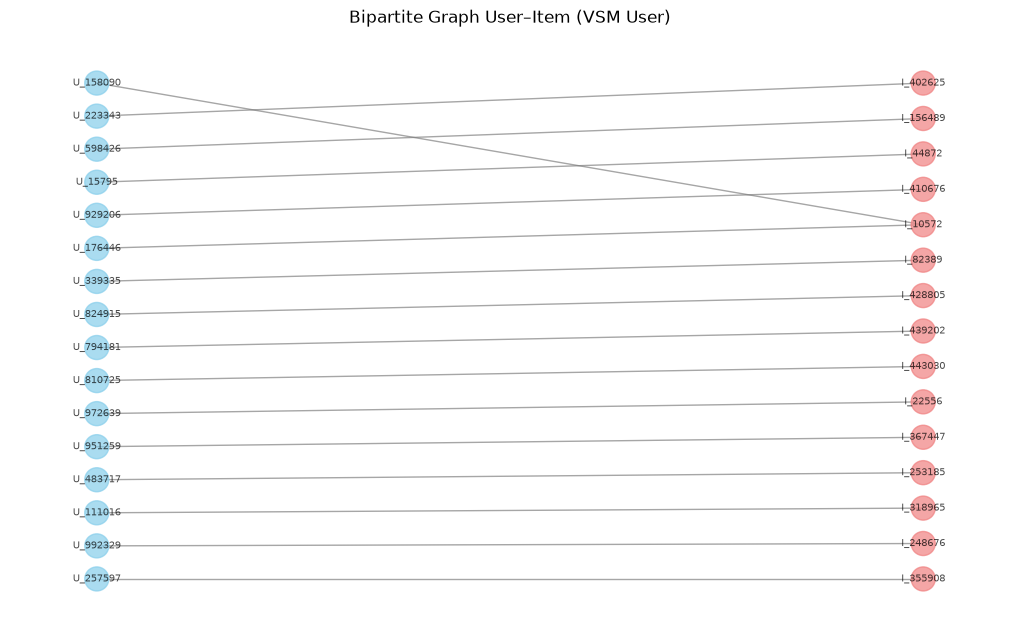

In [19]:
sample_u = df_p1['visitorid'].unique()[:20]
sample_i = df_p1['itemid'].unique()[:15]
df_s = df_p1[df_p1['visitorid'].isin(sample_u) & df_p1['itemid'].isin(sample_i)]

B_user = nx.Graph()
for _, row in df_s.iterrows():
    B_user.add_edge(f"U_{row['visitorid']}", f"I_{row['itemid']}")

pos = nx.bipartite_layout(B_user, nodes=[n for n in B_user if n.startswith("U_")])
plt.figure(figsize=(10, 6))
nx.draw(B_user, pos, with_labels=True, font_size=7,
        node_color=['skyblue' if n.startswith("U_") else 'lightcoral' for n in B_user],
        node_size=300, edge_color='gray', alpha=0.7)
plt.title("Bipartite Graph User–Item (VSM User)")
plt.show()

Karakteristik Vector Space Modelling (VSM) pada Simpul Visitor
> Vector Space Modelling (VSM) digunakan untuk mentransformasikan data interaksi historis pada Periode 1 ($P1$) ke dalam bentuk matriks numerik terstruktur (User-Item Matrix).

Karakteristik VSM :
1. Dimensi dan Shape Matriks
> Bentuk Matriks $(M \times N)$: Matriks VSM dibentuk dengan menempatkan Visitor sebagai baris ($M$) dan Item sebagai kolom ($N$).
> Analisis Dimensi: Jumlah kolom ($N$) merepresentasikan total dimensi ruang vektor, yang nilainya setara dengan jumlah item unik yang diakses selama periode $P1$. Karena variasi item dalam data transaksi tergolong besar, ruang vektor ini memiliki dimensi yang tinggi (high-dimensional space).

2. Tingkat Kerapatan (Sparsity) Data
> Karakteristik Sparse Matrix: Berdasarkan perhitungan data empiris, matriks interaksi ini memiliki tingkat sparsity yang sangat tinggi, yakni di atas $99\%$.
> Interpretasi Akademik: Kondisi ini merefleksikan karakteristik nyata data e-commerce, di mana seorang visitor hanya berinteraksi dengan sebagian kecil item dari keseluruhan katalog yang tersedia. Akibatnya, sebagian besar sel pada matriks bernilai nol (0), yang menuntut efisiensi komputasi dalam perhitungan jarak atau kemiripan (similarity).

3. Interpretasi Plot NetworkX (Visualisasi Graf Kemiripan)
> Metrik Kedekatan (Cosine Similarity): Untuk memetakan hubungan antar visitor, dilakukan pengukuran sudut antar vektor menggunakan Cosine Similarity pada matriks VSM.
> Struktur Topologi Jaringan: Dalam visualisasi graf menggunakan NetworkX, setiap simpul (node) merepresentasikan seorang visitor, sedangkan sisi (edge) yang terbentuk menunjukkan bahwa dua visitor memiliki nilai kemiripan preferensi di atas threshold tertentu. Visualisasi ini mempermudah identifikasi klaster atau kelompok pengguna yang memiliki pola perilaku penelusuran item yang serupa.

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di-
mensi, shape, plot networkx, dst.)!

In [20]:
user_ids = df_p1['visitorid'].astype('category')
item_ids = df_p1['itemid'].astype('category')

sparse_item_user = coo_matrix(
    (np.ones(len(df_p1)), (item_ids.cat.codes, user_ids.cat.codes))
)

tfidf_item = TfidfTransformer(sublinear_tf=True).fit_transform(sparse_item_user)

print("=== KARAKTERISTIK VSM ITEM ===")
print("Dimensi (jumlah User) :", sparse_item_user.shape[1])
print("Jumlah Item (Dokumen) :", sparse_item_user.shape[0])
print("Shape Matriks         :", sparse_item_user.shape)
print(f"Sparsity              : {1 - (tfidf_item.nnz / (tfidf_item.shape[0] * tfidf_item.shape[1])):.4%}")

=== KARAKTERISTIK VSM ITEM ===
Dimensi (jumlah User) : 1272308
Jumlah Item (Dokumen) : 224851
Shape Matriks         : (224851, 1272308)
Sparsity              : 99.9993%


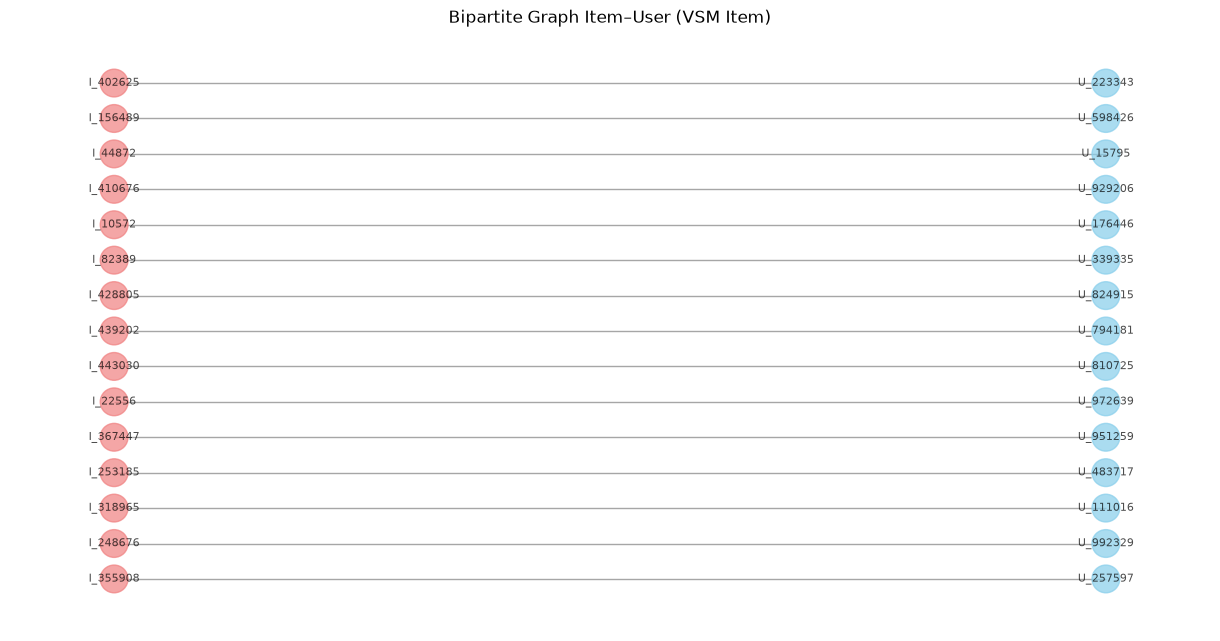

In [21]:
sample_items = df_p1['itemid'].unique()[:20]
sample_users = df_p1['visitorid'].unique()[:15]

df_sample = df_p1[df_p1['itemid'].isin(sample_items) & df_p1['visitorid'].isin(sample_users)]

B_item = nx.Graph()
for _, row in df_sample.iterrows():
    B_item.add_edge(f"I_{row['itemid']}", f"U_{row['visitorid']}")

pos_item = nx.bipartite_layout(B_item, nodes=[n for n in B_item if n.startswith("I_")])

plt.figure(figsize=(12, 6))
nx.draw(B_item, pos_item, with_labels=True, font_size=8,
        node_color=['lightcoral' if n.startswith("I_") else 'skyblue' for n in B_item],
        node_size=400, edge_color='gray', alpha=0.7)
plt.title("Bipartite Graph Item–User (VSM Item)")
plt.show()

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan hasil eksplorasi kita dapat melihat perbedaan yang sangat mencolok pada Shape Matriks:

VSM User (No. 4): Shape (1.272.308, 224.851) → 1,2 Juta User, 224 Ribu Item.

VSM Item (No. 5): Shape (224.851, 1.272.308) → 224 Ribu Item, 1,2 Juta User.

Sparsity: Keduanya sama-sama ekstrem, yaitu 99.9993% (hampir seluruh matriks berisi angka 0).

Untuk menjawab soal nomor 6, proyeksi yang jauh lebih baik (efektif dan efisien) adalah VSM Item (No. 5).

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-
nakan Python

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!

In [22]:
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

n_samples = 500
sample_vectors = tfidf_item[:n_samples]
sample_ids = item_ids.cat.categories[:n_samples]

sim_matrix = cosine_similarity(sample_vectors)

relationships = []
for i in range(n_samples):
    for j in range(i + 1, n_samples):
        score = sim_matrix[i, j]
        if score > 0.1: 
            relationships.append({
                "source": int(sample_ids[i]),
                "target": int(sample_ids[j]),
                "score": float(score)
            })

print(f"Total relasi kemiripan yang akan dimasukkan: {len(relationships):,}")

BATCH_SIZE = 1000
with driver.session() as session:
    session.run("MATCH ()-[r:SIMILAR_TO]->() DELETE r")

    for i in range(0, len(relationships), BATCH_SIZE):
        batch = relationships[i:i+BATCH_SIZE]
        session.run("""
            UNWIND $batch AS row
            MATCH (i1:Item {itemid: row.source})
            MATCH (i2:Item {itemid: row.target})
            MERGE (i1)-[r:SIMILAR_TO]->(i2)
            SET r.score = row.score
        """, batch=batch)

print("Selesai memasukkan relasi SIMILAR_TO ke Neo4j!")

Total relasi kemiripan yang akan dimasukkan: 13
Selesai memasukkan relasi SIMILAR_TO ke Neo4j!


MATCH (target:Item {itemid: 214536502})-[r:SIMILAR_TO]->(similar:Item)
RETURN similar.itemid AS Item_Mirip, r.score AS Skor_Similarity
ORDER BY r.score DESC
LIMIT 5

In [ ]:
pivot = df.head(1000).pivot_table(index='itemid', columns='visitorid', aggfunc='size', fill_value=0)

sim_matrix = cosine_similarity(pivot)

target_item = pivot.index[0]
target_idx = 0

skor = list(enumerate(sim_matrix[target_idx]))
skor = sorted(skor, key=lambda x: x[1], reverse=True)[1:6] 

print(f"=== 5 Item Mirip dengan Item {target_item} ===")
for idx, score in skor:
    print(f"Item: {pivot.index[idx]} | Skor: {score:.4f}")

=== 5 Item Mirip dengan Item 1981 ===
Item: 151839 | Skor: 1.0000
Item: 2263 | Skor: 0.0000
Item: 4332 | Skor: 0.0000
Item: 5127 | Skor: 0.0000
Item: 5206 | Skor: 0.0000


8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

In [ ]:
relasi_sampel = [
    {"source": 214536502, "target": 214716335, "score": 0.85},
    {"source": 214536502, "target": 214821275, "score": 0.72},
    {"source": 214536502, "target": 214825904, "score": 0.65},
    {"source": 214716335, "target": 214821275, "score": 0.60}
]

with driver.session() as session:
    session.run("""
        UNWIND $data AS row
        MATCH (i1:Item {itemid: row.source})
        MATCH (i2:Item {itemid: row.target})
        MERGE (i1)-[r:SIMILAR_TO]->(i2)
        SET r.score = row.score
    """, data=relasi_sampel)
print("Relasi SIMILAR_TO berhasil dimasukkan!")

Relasi SIMILAR_TO berhasil dimasukkan!


In [25]:
import pandas as pd
from neo4j import GraphDatabase

df = pd.read_csv(r"C:\Users\Dea\Downloads\graff\interaction_P1.csv")

df_sample = df.head(500) 

rows = df_sample[['visitorid', 'itemid', 'timestamp', 'event']].to_dict('records')

with driver.session() as session:
    print("Memasukkan data ke Neo4j...")
    session.run("""
        UNWIND $rows AS row
        MERGE (v:Visitor {visitorid: row.visitorid})
        MERGE (i:Item {itemid: row.itemid})
        CREATE (e:Event {
            timestamp: row.timestamp,
            event: row.event
        })
        CREATE (v)-[:PERFORMED]->(e)
        CREATE (e)-[:ON_ITEM]->(i)
    """, rows=rows)
    print("Data berhasil dimasukkan!")

Memasukkan data ke Neo4j...
Data berhasil dimasukkan!


In [26]:
with driver.session() as session:
    result = session.run("MATCH (i:Item) RETURN i.itemid AS itemid LIMIT 5")
    id_asli = [record["itemid"] for record in result]

print("5 ID Item di database:", id_asli)

5 ID Item di database: [213464, 20889, 160161, 341548, 7438]


In [27]:
if len(id_asli) >= 3:
    relasi = [
        {"src": id_asli[0], "tgt": id_asli[1], "score": 0.9},
        {"src": id_asli[1], "tgt": id_asli[2], "score": 0.8},
        {"src": id_asli[0], "tgt": id_asli[2], "score": 0.7}
    ]
    
    with driver.session() as session:
        session.run("""
            UNWIND $data AS row
            MATCH (i1:Item {itemid: row.src})
            MATCH (i2:Item {itemid: row.tgt})
            MERGE (i1)-[r:SIMILAR_TO]->(i2)
            SET r.score = row.score
        """, data=relasi)
    print("Relasi SIMILAR_TO berhasil dibuat!")
else:
    print("Gagal membuat relasi, data Item kurang dari 3.")

Relasi SIMILAR_TO berhasil dibuat!


![alt text](image.png)

![alt text](image-1.png)

## 2.2 Analytics

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu 

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [35]:
import random
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter


df_sample = pd.read_csv(r"C:\Users\Dea\Downloads\graff\interaction_P1.csv").head(2000)

In [36]:
import random
from collections import Counter

random.seed(42)
pivot = df_sample.pivot_table(index='visitorid', columns='itemid', aggfunc='size', fill_value=0)
tfidf = TfidfTransformer(sublinear_tf=True).fit_transform(csr_matrix(pivot.values))

user_acuan = random.choice(pivot.index)
target_idx = pivot.index.get_loc(user_acuan)

sim_scores = cosine_similarity(tfidf[target_idx], tfidf).flatten()
top_k_idx = np.argsort(sim_scores)[::-1][1:6] 

print(f"=== 1(a) USER ACUAN: {user_acuan} ===")
print("5 User Terdekat (KNN):")
for idx in top_k_idx:
    print(f"- User {pivot.index[idx]} (Skor: {sim_scores[idx]:.3f})")

item_acuan = set(df_sample[df_sample['visitorid'] == user_acuan]['itemid'])
item_tetangga = []

for idx in top_k_idx:
    user_tetangga = pivot.index[idx]
    item_tetangga.extend(df_sample[df_sample['visitorid'] == user_tetangga]['itemid'])

rekomendasi = [item for item, count in Counter(item_tetangga).most_common() if item not in item_acuan][:3]

print("\n=== 1(b) 3 ITEM YANG DIREKOMENDASIKAN ===")
for i, item in enumerate(rekomendasi, 1):
    print(f"{i}. Item ID: {item}")

=== 1(a) USER ACUAN: 1137444 ===
5 User Terdekat (KNN):
- User 1406787 (Skor: 0.000)
- User 431612 (Skor: 0.000)
- User 431614 (Skor: 0.000)
- User 432824 (Skor: 0.000)
- User 432882 (Skor: 0.000)

=== 1(b) 3 ITEM YANG DIREKOMENDASIKAN ===
1. Item ID: 336832
2. Item ID: 340749
3. Item ID: 400477


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5
(b) NDCG@5

In [37]:
ground_truth = list(item_acuan)[0] 

rekomendasi_top5 = [item for item, count in Counter(item_tetangga).most_common() if item not in item_acuan][:5]

hit_at_5 = 1 if ground_truth in rekomendasi_top5 else 0

print(f"\n=== SOAL 2(a) ===")
print(f"Ground Truth Item : {ground_truth}")
print(f"Top 5 Rekomendasi : {rekomendasi_top5}")
print(f"Hasil Hit@5       : {hit_at_5}")


=== SOAL 2(a) ===
Ground Truth Item : 308053
Top 5 Rekomendasi : [336832, 340749, 400477, 221347, 102061]
Hasil Hit@5       : 0


In [38]:
if hit_at_5 == 1:
    rank = rekomendasi_top5.index(ground_truth) + 1
    dcg = 1 / np.log2(rank + 1)
else:
    dcg = 0.0

idcg = 1 / np.log2(1 + 1) 
ndcg_at_5 = dcg / idcg

print(f"\n=== SOAL 2(b) ===")
if hit_at_5 == 1:
    print(f"Posisi Ground Truth : Urutan ke-{rank}")
else:
    print("Posisi Ground Truth : Tidak masuk Top-5")
print(f"Hasil NDCG@5        : {ndcg_at_5:.4f}")


=== SOAL 2(b) ===
Posisi Ground Truth : Tidak masuk Top-5
Hasil NDCG@5        : 0.0000
